In [1]:
import torch
import torchvision

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.15.0+cpu
Torchvision version: 0.29.2+cpu
CUDA available: False


In [4]:
from pathlib import Path

# Define cleaned dataset location
CLEANED_DIR = Path(
    r"A:\Crop-Disease-Detection\dataset\cleaned"
)

# Verify the directory
print("Cleaned dataset exists:", CLEANED_DIR.exists())

# Verify splits
for split in ["Train", "Val", "Test"]:
    print(split, "exists:", (CLEANED_DIR / split).exists())

Cleaned dataset exists: True
Train exists: True
Val exists: True
Test exists: True


In [5]:
from PIL import Image
from torchvision import transforms
from pathlib import Path

# Select one sample image from the cleaned dataset
sample_image_path = next(
    (CLEANED_DIR / "Train").glob("*/*.jpg"),
    None
)

# Load image
image = Image.open(sample_image_path).convert("RGB")

print("Original image size:", image.size)
print("Original image mode:", image.mode)

# Define ResNet50 preprocessing
preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Apply preprocessing
image_tensor = preprocess(image)

print("\nPreprocessed tensor shape:", image_tensor.shape)
print("Minimum tensor value:", image_tensor.min().item())
print("Maximum tensor value:", image_tensor.max().item())

Original image size: (256, 256)
Original image mode: RGB

Preprocessed tensor shape: torch.Size([3, 224, 224])
Minimum tensor value: -1.7582842111587524
Maximum tensor value: 2.0996952056884766


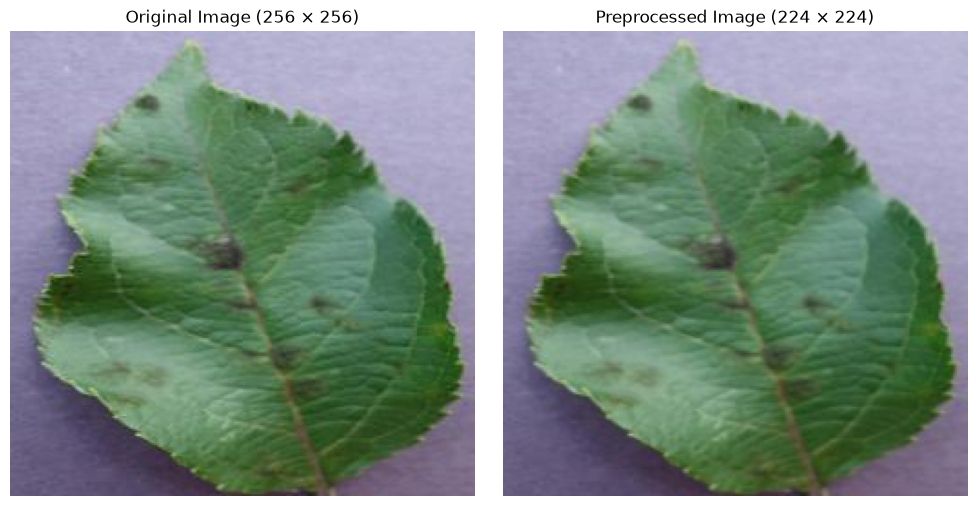

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# Convert normalized tensor back to displayable RGB values
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

tensor_image = image_tensor.permute(1, 2, 0).numpy()

display_image = tensor_image * std + mean
display_image = np.clip(display_image, 0, 1)

# Display both images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image (256 × 256)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(display_image)
plt.title("Preprocessed Image (224 × 224)")
plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
from torchvision import transforms

# Basic preprocessing for ResNet50
resnet50_preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("ResNet50 preprocessing pipeline created!")

ResNet50 preprocessing pipeline created!


In [8]:
from torchvision import transforms

train_transform = transforms.Compose([

    # Resize image
    transforms.Resize((224, 224)),

    # Random horizontal flip
    transforms.RandomHorizontalFlip(p=0.5),

    # Random vertical flip
    transforms.RandomVerticalFlip(p=0.5),

    # Random rotation between -15 and +15 degrees
    transforms.RandomRotation(degrees=15),

    # Slight color variations
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1
    ),

    # Convert image into tensor
    transforms.ToTensor(),

    # ResNet50 normalization
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Training augmentation pipeline created!")

Training augmentation pipeline created!


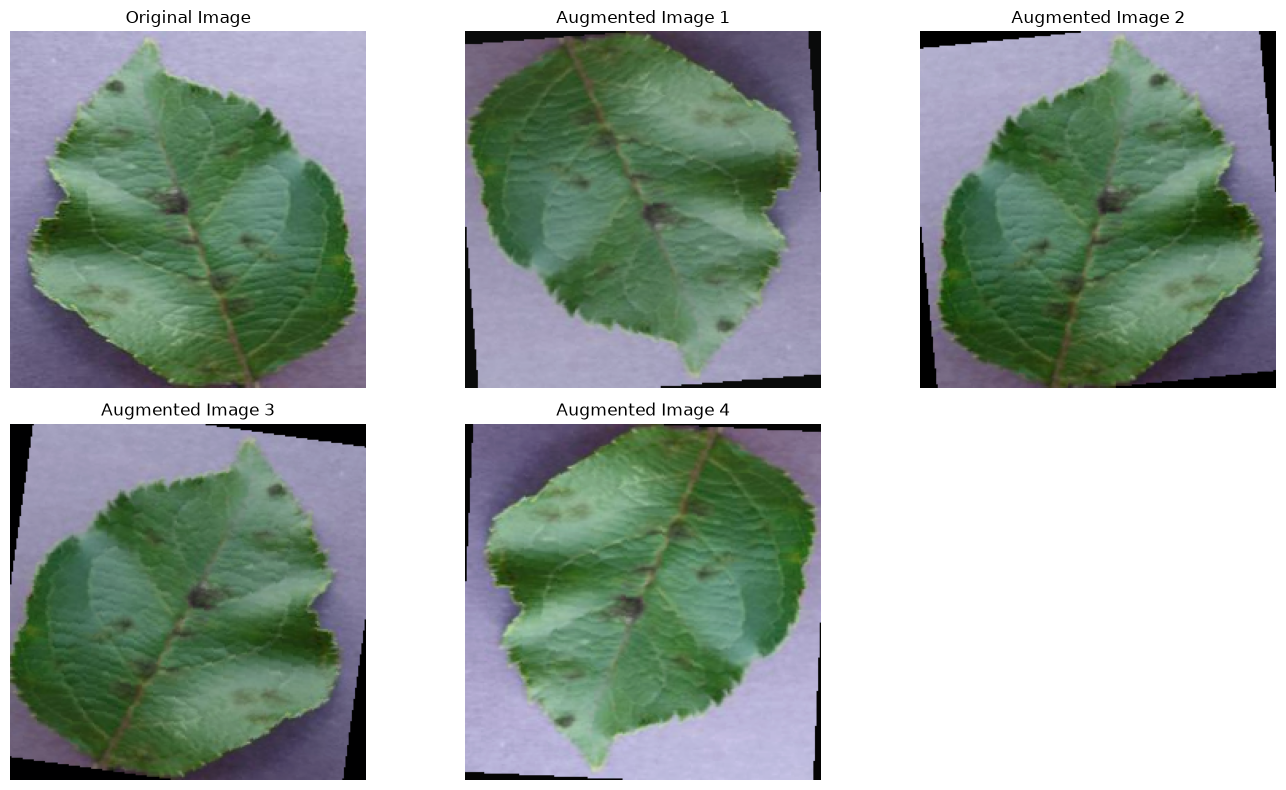

In [9]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# Find one training image
sample_image_path = next(
    path for path in (CLEANED_DIR / "Train").glob("*/*")
    if path.suffix.lower() in [".jpg", ".jpeg", ".png"]
)

# Load original image
sample_image = Image.open(sample_image_path).convert("RGB")

# ResNet50 normalization values
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

# Display original and augmented images
plt.figure(figsize=(14, 8))

plt.subplot(2, 3, 1)
plt.imshow(sample_image)
plt.title("Original Image")
plt.axis("off")

for i in range(4):

    # Apply random augmentation
    augmented_tensor = train_transform(sample_image)

    # Convert tensor to displayable image
    augmented_image = augmented_tensor.permute(1, 2, 0).numpy()

    # Reverse normalization for visualization
    augmented_image = augmented_image * std + mean
    augmented_image = np.clip(augmented_image, 0, 1)

    plt.subplot(2, 3, i + 2)
    plt.imshow(augmented_image)
    plt.title(f"Augmented Image {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
train_transform = transforms.Compose([

    transforms.Resize((224, 224)),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomVerticalFlip(p=0.5),

    # Fill empty rotation areas with neutral color
    transforms.RandomRotation(
        degrees=15,
        fill=(124, 116, 104)
    ),

    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Improved augmentation pipeline created!")

Improved augmentation pipeline created!
